## 1. Loading Dataset

In [15]:
import pandas as pd
store_data = pd.read_csv("C:\\Users\\kayce\\OneDrive\\Documents\\Sales Forecasting and Business Intelligence\\data\\processed\\superstore_cleaned.csv", encoding="latin1")

store_data["Order Date"] = pd.to_datetime(
    store_data["Order Date"]
)

monthly_sales = (
    store_data
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)
monthly_sales.head()

Order Date
2014-01-01    28953.706
2014-02-01    12743.108
2014-03-01    54801.906
2014-04-01    24710.016
2014-05-01    29639.834
Freq: MS, Name: Sales, dtype: float64

In [16]:
monthly_sales.shape

(48,)

In [17]:
train = monthly_sales.iloc[:-8]
test = monthly_sales.iloc[-8:]

In [18]:
# Moving Average Model
window = 3

history = train.tolist()
moving_average_predictions = []

for _ in range(len(test)):
    prediction = sum(history[-window:]) / window
    moving_average_predictions.append(prediction)
    history.append(prediction)

moving_average_predictions = pd.Series(
    moving_average_predictions,
    index=test.index,
    name="Moving Average"
)

moving_average_predictions

Order Date
2017-05-01    54619.191600
2017-06-01    56155.092333
2017-07-01    49948.761844
2017-08-01    53574.348593
2017-09-01    53226.067590
2017-10-01    52249.726009
2017-11-01    53016.714064
2017-12-01    52830.835888
Freq: MS, Name: Moving Average, dtype: float64

In [19]:
# Fit the Holt-Winters model
from statsmodels.tsa.holtwinters import ExponentialSmoothing
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

hw_predictions = hw_model.forecast(len(test))

hw_predictions

2017-05-01    56454.814241
2017-06-01    42633.235720
2017-07-01    45941.995467
2017-08-01    57242.012403
2017-09-01    79262.062342
2017-10-01    46350.553723
2017-11-01    69977.263213
2017-12-01    71053.367334
Freq: MS, dtype: float64

In [20]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_predictions = sarima_model.forecast(steps=len(test))

sarima_predictions

C:\Users\kayce\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


2017-05-01    43635.055850
2017-06-01    54395.882246
2017-07-01    54950.633877
2017-08-01    66880.805369
2017-09-01    88272.966151
2017-10-01    52809.645852
2017-11-01    67944.463790
2017-12-01    66998.338372
Freq: MS, Name: predicted_mean, dtype: float64

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions = {
    "Moving Average": moving_average_predictions,
    "Holt-Winters": hw_predictions,
    "SARIMA": sarima_predictions
}

results = []

for model_name, forecast in predictions.items():
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("MAE")

results_df

,Model,MAE,RMSE
2,SARIMA,9620.000561,11437.562392
1,Holt-Winters,13152.006549,14336.692037
0,Moving Average,15412.706943,18424.366244


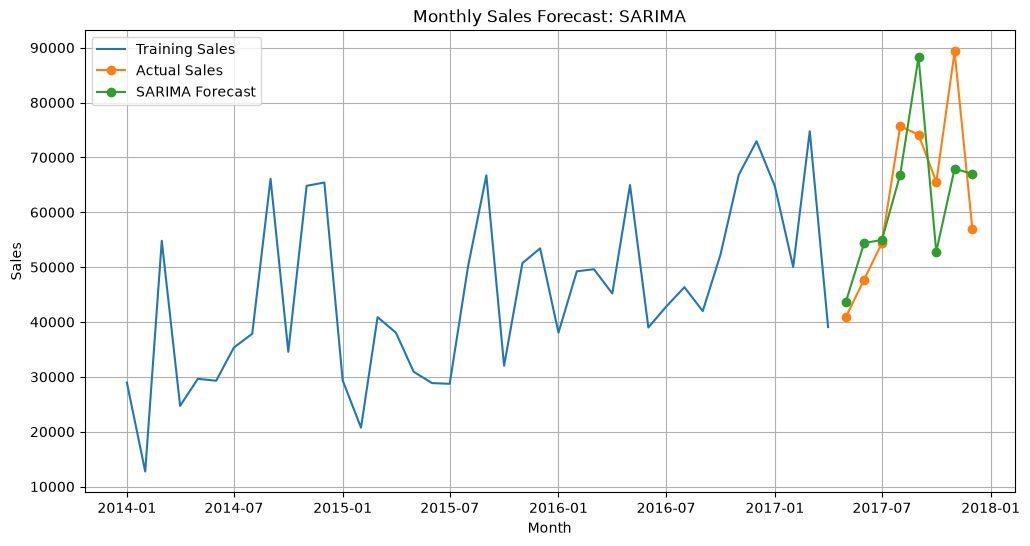

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(train.index, train, label="Training Sales")
plt.plot(test.index, test, label="Actual Sales", marker="o")
plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Forecast",
    marker="o"
)

plt.title("Monthly Sales Forecast: SARIMA")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [24]:

# Train the final SARIMA model on all historical data
final_sarima = SARIMAX(
    monthly_sales,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# Forecast the next 12 months
future_forecast = final_sarima.forecast(steps=12)

future_forecast


C:\Users\kayce\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


2018-01-01    61529.703755
2018-02-01    65297.335544
2018-03-01    73401.736124
2018-04-01    72893.157675
2018-05-01    80367.559841
2018-06-01    66359.576534
2018-07-01    67732.189959
2018-08-01    71369.469168
2018-09-01    79537.900293
2018-10-01    70567.284380
2018-11-01    82802.265249
2018-12-01    93379.213599
Freq: MS, Name: predicted_mean, dtype: float64

In [25]:

forecast_df = pd.DataFrame({
    "Forecast Date": future_forecast.index,
    "Forecast Sales": future_forecast.values
})

forecast_df["Forecast Sales"] = forecast_df["Forecast Sales"].round(2)

forecast_df


,Forecast Date,Forecast Sales
0,2018-01-01,61529.70
1,2018-02-01,65297.34
2,2018-03-01,73401.74
3,2018-04-01,72893.16
4,2018-05-01,80367.56
5,2018-06-01,66359.58
6,2018-07-01,67732.19
7,2018-08-01,71369.47
8,2018-09-01,79537.90
9,2018-10-01,70567.28


In [26]:

from pathlib import Path

output_path = Path(
    r"C:\Users\kayce\OneDrive\Documents\Sales Forecasting and Business Intelligence\data\processed"
) / "sarima_sales_forecast.csv"

forecast_df.to_csv(output_path, index=False)

print("Forecast saved successfully!")
print("Location:", output_path)


Forecast saved successfully!
Location: C:\Users\kayce\OneDrive\Documents\Sales Forecasting and Business Intelligence\data\processed\sarima_sales_forecast.csv


## Forecasting Results and Conclusion

### Model Selection

Three forecasting approaches were evaluated: Moving Average, Holt-Winters Exponential Smoothing, and SARIMA. Their performance was compared using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

The original SARIMA model, with order (1, 1, 1) and seasonal order (1, 1, 1, 12), achieved the lowest test MAE and RMSE among the three models. It was therefore selected as the final forecasting model.

### Final Forecast

The selected SARIMA model was refitted using the complete historical monthly sales dataset and used to forecast sales for the next 12 months beyond the available data.

The forecast was exported to `data/processed/sarima_sales_forecast.csv` for use in the project's subsequent reporting and visualization stage.

### Limitations

The dataset covers January 2014 to December 2017. Therefore, the forecast represents the 12 months of 2018 and demonstrates the forecasting workflow rather than providing a current sales forecast. Forecast accuracy may also be affected by changes in business conditions that are not represented in the historical data.

### Conclusion

The analysis combined exploratory data analysis, model comparison, and seasonal time-series forecasting to examine historical sales patterns and generate future sales estimates. SARIMA performed best among the evaluated models on the selected test period. The resulting forecast provides a basis for further visualization and business intelligence reporting.